In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Load dataset
df = pd.read_excel(
    r"I:\Muzzamil Data Analyst\OBSIS Intership Project\DataAnalytics-L1-CustomerSegmentation\Online Retail.xlsx"
)

# Display first 5 rows
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

display(df.head())

Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing values:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


Duplicate rows: 5268


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [8]:
# Check cancelled invoices
cancelled_invoices = df["InvoiceNo"].astype(str).str.startswith("C")
print("Cancelled invoice rows:", cancelled_invoices.sum())

# Check negative quantities
print("Rows with negative quantity:", (df["Quantity"] < 0).sum())

# Check zero quantities
print("Rows with zero quantity:", (df["Quantity"] == 0).sum())

# Check zero or negative unit prices
print("Rows with zero unit price:", (df["UnitPrice"] == 0).sum())
print("Rows with negative unit price:", (df["UnitPrice"] < 0).sum())

# Check unique customers and invoices
print("Unique customer IDs:", df["CustomerID"].nunique())
print("Unique invoice numbers:", df["InvoiceNo"].nunique())

Cancelled invoice rows: 9288
Rows with negative quantity: 10624
Rows with zero quantity: 0
Rows with zero unit price: 2515
Rows with negative unit price: 2
Unique customer IDs: 4372
Unique invoice numbers: 25900


In [10]:
# Keep the original dataset unchanged
df_clean = df.copy()

# 1. Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# 2. Remove rows without a customer ID
df_clean = df_clean.dropna(subset=["CustomerID"])

# 3. Remove cancelled invoices
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# 4. Keep positive quantities and unit prices
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
]

# 5. Ensure customer IDs are integers
df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)

# 6. Calculate transaction line value
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# Check the cleaned dataset
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Unique customers:", df_clean["CustomerID"].nunique())
print("Missing values after cleaning:")
display(df_clean.isnull().sum())

Original rows: 541909
Cleaned rows: 392692
Unique customers: 4338
Missing values after cleaning:


InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Revenue        0
dtype: int64

### Data Cleaning — Observations

1. The original dataset contained 541,909 rows.
2. Exact duplicate rows were removed.
3. Records without CustomerID were excluded because customer-level segmentation requires an identifiable customer.
4. Cancelled invoices and records with non-positive quantities or unit prices were excluded from the purchase analysis.
5. The cleaned dataset contains 392,692 rows and 4,338 unique customers.
6. No missing values remain in the cleaned dataset.
7. A Revenue column was created by multiplying Quantity by UnitPrice.

**Note:** Returns and cancelled transactions are excluded from this analysis. Therefore, the monetary values represent positive purchase transactions rather than net spending after returns.

In [13]:
# Set the reference date to one day after the latest transaction
reference_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate RFM metrics for each customer
rfm = df_clean.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

# Display the first 5 customers
display(rfm.head())

# Summary statistics
print("RFM shape:", rfm.shape)
display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))

,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


RFM shape: (4338, 4)


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02


### RFM Analysis — Initial Observations

1. The RFM dataset contains 4,338 unique customers.
2. Average recency is 92.54 days, while median recency is 51 days.
3. Customers made an average of 4.27 distinct invoices, with a median of 2 invoices.
4. Average monetary value is 2,048.69, compared with a median of 668.57.
5. Monetary values vary considerably, with a maximum of 280,206.02.
6. The differences between the mean and median suggest that frequency and monetary value may be right-skewed.
7. **Next step:** Standardize the RFM features before clustering so differences in scale do not dominate the K-Means algorithm.

In [16]:
from sklearn.preprocessing import StandardScaler

# Select the three RFM features
rfm_features = rfm[["Recency", "Frequency", "Monetary"]].copy()

# Standardize the features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_features)

print("Original RFM shape:", rfm_features.shape)
print("Scaled RFM shape:", rfm_scaled.shape)

# Preview standardized values
display(
    pd.DataFrame(
        rfm_scaled,
        columns=["Recency_scaled", "Frequency_scaled", "Monetary_scaled"]
    ).head()
)

Original RFM shape: (4338, 3)
Scaled RFM shape: (4338, 3)


,Recency_scaled,Frequency_scaled,Monetary_scaled
0,2.334574,-0.425097,8.363010
1,-0.905340,0.354417,0.251699
2,-0.175360,-0.035340,-0.027988
3,-0.735345,-0.425097,-0.032406
4,2.174578,-0.425097,-0.190812


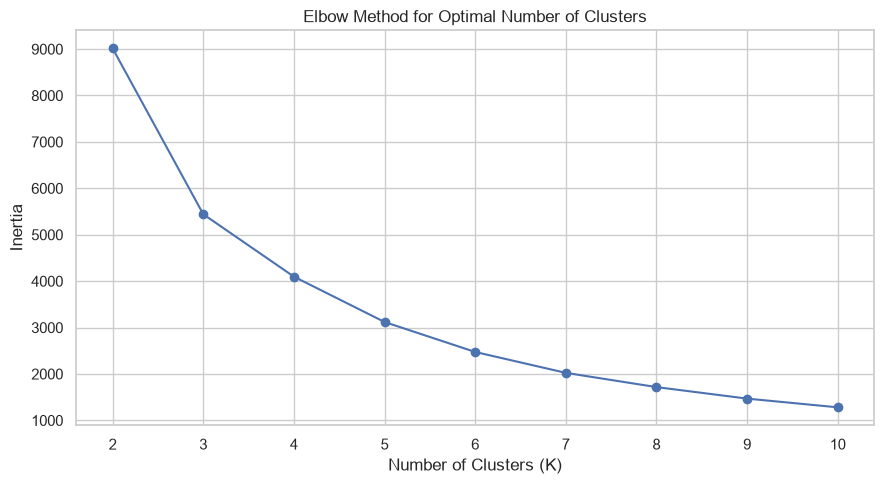

In [18]:
from sklearn.cluster import KMeans

inertia_values = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(rfm_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(k_values, inertia_values, marker="o")

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

### Elbow Method — Observations

1. The Elbow Method was applied for cluster counts from K = 2 to K = 10.
2. Inertia decreases as the number of clusters increases.
3. The curve shows a noticeable reduction in the rate of improvement around K = 4.
4. Based on the plotted curve, K = 4 was selected as an initial clustering choice.
5. The resulting customer segments will be examined to determine whether they are distinct and useful for marketing decisions.

In [21]:
# Apply K-Means clustering
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Assign a cluster to each customer
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

# Check cluster assignments
display(rfm.head(10))

print("\nCustomers in each cluster:")
display(rfm["Cluster"].value_counts().sort_index())

,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,77183.60,3
1,12347,2,7,4310.00,0
2,12348,75,4,1797.24,0
3,12349,19,1,1757.55,0
4,12350,310,1,334.40,1
5,12352,36,8,2506.04,0
6,12353,204,1,89.00,1
7,12354,232,1,1079.40,1
8,12355,214,1,459.40,1
9,12356,23,3,2811.43,0



Customers in each cluster:


Cluster
0    3054
1    1067
2      13
3     204
Name: count, dtype: int64

In [23]:
# Calculate average RFM values for each cluster
cluster_profile = rfm.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

display(cluster_profile)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,3054,43.70,3.68,1353.63
1,1067,248.08,1.55,478.85
2,13,7.38,82.54,127187.96
3,204,15.50,22.33,12690.50


### K-Means Cluster Profiling — Observations

1. Cluster 0 is the largest segment, containing 3,054 customers with average recency of 43.70 days and average monetary value of 1,353.63.
2. Cluster 1 contains 1,067 customers and has the highest average recency (248.08 days), suggesting that these customers may need reactivation campaigns.
3. Cluster 2 contains only 13 customers but has the highest average frequency (82.54 invoices) and monetary value (127,187.96).
4. Cluster 3 contains 204 customers with average frequency of 22.33 invoices and average monetary value of 12,690.50.
5. **Business recommendation:** Use different marketing strategies for each segment, while checking individual customer records and validating the unusually high-value Cluster 2 before implementing VIP campaigns.

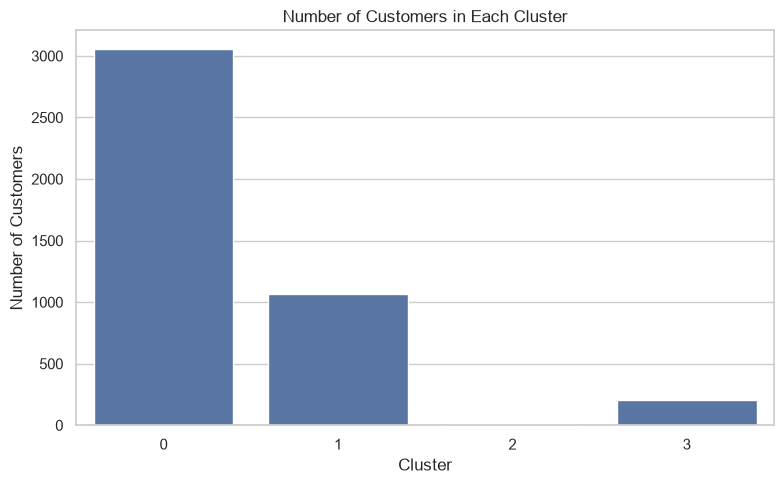

In [26]:
cluster_counts = rfm["Cluster"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

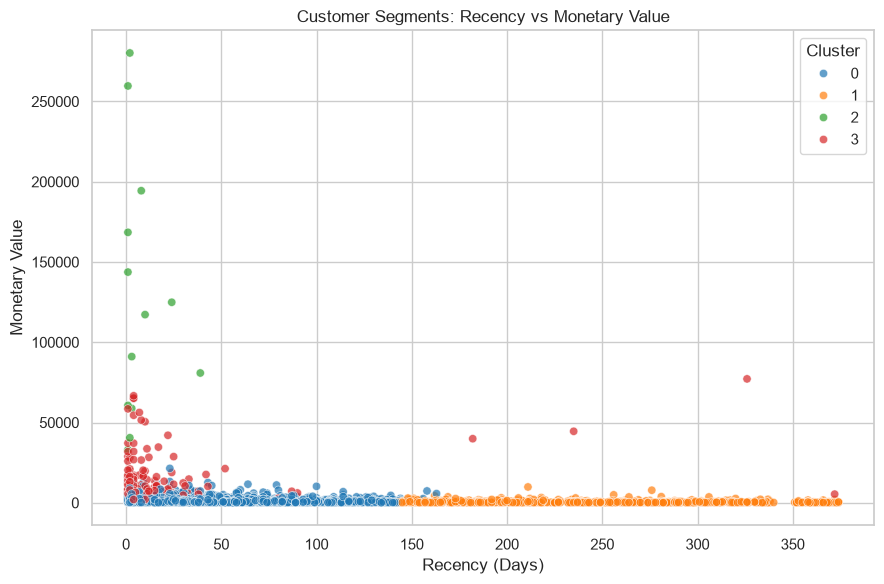

In [28]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="tab10",
    alpha=0.7
)

plt.title("Customer Segments: Recency vs Monetary Value")
plt.xlabel("Recency (Days)")
plt.ylabel("Monetary Value")
plt.tight_layout()
plt.show()

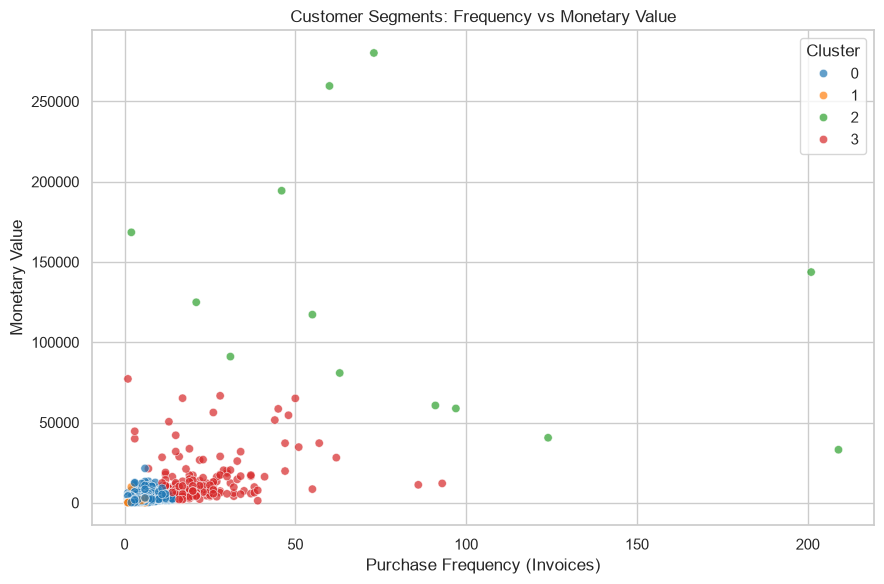

In [30]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="tab10",
    alpha=0.7
)

plt.title("Customer Segments: Frequency vs Monetary Value")
plt.xlabel("Purchase Frequency (Invoices)")
plt.ylabel("Monetary Value")
plt.tight_layout()
plt.show()

### Customer Cluster Visualizations — Observations

1. The Recency vs Monetary plot compares how recently customers purchased with their total spending.
2. The Frequency vs Monetary plot compares the number of distinct invoices with total customer spending.
3. The cluster profiles indicate that Cluster 1 contains customers with long periods since their last purchase and relatively low spending.
4. Cluster 2 contains a small number of very high-frequency, high-spending customers.
5. Cluster 3 contains customers with relatively high purchase frequency and monetary value.
6. **Business recommendation:** Use these visualizations alongside the cluster summary to design retention, reactivation, and loyalty campaigns.